In [5]:
import matplotlib
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.special.cython_special import stdtrit
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, brier_score_loss
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, ParameterGrid
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import matplotlib.pyplot as plt
from sklearn.base import clone
from scipy import special

In [6]:
train_df = pd.read_csv("/Users/halos/Downloads/stop_search_train1.csv", index_col=0)

# Preprocessing before pipeline and modeling
## We drop unnecessary columns, define categorical and discrete/numerical columns for imputation, and convert categorical variables into strings

In [7]:
# Dropping unnecessary columns for modeling
train_date = train_df["event_dt"]
train_df = train_df.drop(["event_dt", "orig_age", "vital_flag", "orig_height", "orig_weight", "BMI", "year", "Zone", "Latitude", "Longitude", "SubjectID"], axis = 1)

# Unfloating zip code
train_df["Zip"] = train_df["Zip"].astype("Int64")
# Defining categorical columns
cat_cols = ["SubjectRace", "Zip", "District", "StopDescription"]
# Defining discrete/numerical columns
dis_cols = ["SubjectGender", "SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "SubjectHasPhotoID", "hour", "night", "isDriver"]
# Numerical columns we would like to scale
scale_cols = ["SubjectAge", "SubjectHeight", "SubjectWeight", "VehicleYear", "hour"]
# Binary columns
bin_cols = ["SubjectGender", "SubjectHasPhotoID", "night", "isDriver"]

# Converting variables into strings
train_df[cat_cols] = train_df[cat_cols].astype(str)

In [8]:
target = "search_occurred"
X_train = train_df.drop([target], axis = 1)[cat_cols + dis_cols]
y_train = train_df[target]

# Defining classes to build pipeline
## CatBinner groups sparse labels in categorical variables in an Other category. RoundImputed is used after imputation, to ensure imputed numerical values are discrete

In [9]:
class CatBinner(BaseEstimator, TransformerMixin):
    def __init__(self, cols, min_freq=0.01, fill_value="Other"):
        self.cols = cols
        self.min_freq = min_freq
        self.fill_value = fill_value

    def fit(self, X, y=None):
        self.keep_labels = {}
        for c in self.cols:
            freq = X[c].value_counts(normalize=True)
            self.keep_labels[c] = freq[freq >= self.min_freq].index.tolist()

        return self

    def transform(self, X):
        X_copy = X.copy()
        for c in self.cols:
            labels = self.keep_labels[c]
            X_copy[c] = np.where(X_copy[c].isin(labels) | X_copy[c].isna(), X_copy[c], self.fill_value)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class RoundImputed(BaseEstimator, TransformerMixin):
    def __init__(self, cols):
        self.cols = cols

    def fit(self, X, y=None):
        rounded = X[self.cols].round()
        self.min_ = rounded.min()
        self.max_ = rounded.max()
        return self

    def transform(self, X):
        X_copy = X.copy()
        X_copy[self.cols] = X_copy[self.cols].round().clip(self.min_, self.max_, axis=1)
        return X_copy

    def set_output(self, *, transform=None):
        return self

class OrdEncoder(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols, inner):
        self.cat_cols = cat_cols
        self.inner = inner

    def _encode(self, X):
        X_enc = X.copy()
        X_enc[self.cat_cols] = self.encoder_.transform(X[self.cat_cols])
        return X_enc

    def _decode(self, X_imp):
        X_dec = X_imp.copy()
        X_dec[self.cat_cols] = self.encoder_.inverse_transform(X_imp[self.cat_cols])
        return X_dec

    def fit_transform(self, X, y=None):
        self.encoder_ = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan)
        self.encoder_.fit(X[self.cat_cols])
        self.inner_ = clone(self.inner)
        return self._decode(self.inner_.fit_transform(self._encode(X), y))

    def fit(self, X, y=None):
        self.fit_transform(X, y)
        return self

    def transform(self, X):
        return self._decode(self.inner_.transform(self._encode(X)))

    def set_output(self, *, transform=None):
        return self

# Building pipeline
## Define a function to construct pipeline given model, and discrete and categorical columns

In [10]:
def build_pipeline(model, cat_cols, dis_cols, scale_cols):
    imputer = IterativeImputer(estimator=HistGradientBoostingRegressor(max_iter=50, random_state=10), skip_complete=True, max_iter=5, tol=1e-2, random_state=10)

    impute = Pipeline([
        ("imputer", imputer),
        ("round", RoundImputed(cols=cat_cols + dis_cols)),
    ])

    impute.set_output(transform="pandas")

    encode = ColumnTransformer([("encode", OneHotEncoder(handle_unknown="ignore"), cat_cols), ("scale", StandardScaler(), scale_cols)], remainder="passthrough", verbose_feature_names_out=False)

    pipeline = Pipeline([
        ("bin", CatBinner(cols=cat_cols, min_freq=0.01, fill_value="Other")),
        ("imputer", OrdEncoder(cat_cols, impute)),
        ("encode", encode),
        ("model", model)
    ], memory="cache_dir")

    return pipeline

## Defining ECE scorer

In [11]:
def expected_calibration_error(y_true, y_prob, n_bins=20):
    bin_edges = np.linspace(0, 1, n_bins + 1)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    ece = 0.0
    for i in range(n_bins):
        bin_mask = (y_prob >= bin_edges[i]) & (y_prob <= bin_edges[i + 1])
        if np.any(bin_mask):
            bin_accuracy = np.mean(y_true[bin_mask])
            bin_confidence = bin_centers[i]
            ece += np.abs(bin_confidence - bin_accuracy) * np.sum(bin_mask)
    ece /= y_true.size
    return ece

ece = make_scorer(expected_calibration_error, greater_is_better=False, response_method="predict_proba", n_bins = 20)

# Modeling
## Logistic regression

In [12]:
# USE OPTIMAL PARAMETERS FOUND IN TUNING
lr = LogisticRegression(l1_ratio=1, C = 0.004832930238571752, max_iter = 1000, random_state=10, solver="saga")

pipeline = build_pipeline(lr, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

lr_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Program Files\WindowsApps\PythonSoftwareFoundation.Python.3.13_3.13.3824.0_x64__qbz5n2kfra8p0\Lib\subprocess.py", line 554, in run
    

[CV] END .................................................... total time=  25.3s


C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\impute\_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


[CV] END .................................................... total time=  25.2s


C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\impute\_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


[CV] END .................................................... total time=  20.8s


... (10 outputs left out)

C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\impute\_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


[CV] END .................................................... total time=  23.3s


C:\Users\halos\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\sklearn\linear_model\_logistic.py:1196: UserWarning: l1_ratio parameter is only used when penalty is 'elasticnet'. Got (penalty=l2)
  warnings.warn(


[CV] END .................................................... total time=  19.1s


## Decision Tree

In [13]:
dt = DecisionTreeClassifier(criterion = "entropy", max_depth = 9, min_samples_leaf = 31, min_samples_split = 29, random_state=10)

pipeline = build_pipeline(dt, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

dt_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=   2.6s
[CV] END .................................................... total time=   2.2s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   1.9s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   2.1s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   2.0s
[CV] END .................................................... total time=   2.2s
[CV] END .................................................... total time=   1.8s


## Random Forest

In [14]:
rf = RandomForestClassifier(criterion="gini", max_depth=None, min_samples_split=13, min_samples_leaf=11, max_features="log2", random_state=10)

pipeline = build_pipeline(rf, cat_cols, dis_cols, scale_cols)

cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=10)

rf_cross_val_scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring={"average_precision":"average_precision", "roc_auc":"roc_auc", "neg_brier_score":"neg_brier_score", "neg_ece":ece}, return_train_score=True, error_score="raise", verbose=2)

[CV] END .................................................... total time=  39.6s
[CV] END .................................................... total time=  45.9s
[CV] END .................................................... total time=  41.3s
[CV] END .................................................... total time=  52.2s
[CV] END .................................................... total time= 1.2min
[CV] END .................................................... total time=  59.6s
[CV] END .................................................... total time=  33.1s
[CV] END .................................................... total time=  33.0s
[CV] END .................................................... total time=  33.5s
[CV] END .................................................... total time=  33.1s


# Evaluating metrics

In [15]:
# Saving results
lr_scores = pd.DataFrame(lr_cross_val_scores)
dt_scores = pd.DataFrame(dt_cross_val_scores)
rf_scores = pd.DataFrame(rf_cross_val_scores)

# Making brier and ece nonnegative
lr_scores["test_brier_score"], lr_scores["train_brier_score"], lr_scores["test_ece"], lr_scores["train_ece"] = -lr_scores["test_neg_brier_score"], -lr_scores["train_neg_brier_score"], -lr_scores["test_neg_ece"], -lr_scores["train_neg_ece"]

dt_scores["test_brier_score"], dt_scores["train_brier_score"], dt_scores["test_ece"], dt_scores["train_ece"] = -dt_scores["test_neg_brier_score"], -dt_scores["train_neg_brier_score"], -dt_scores["test_neg_ece"], -dt_scores["train_neg_ece"]

rf_scores["test_brier_score"], rf_scores["train_brier_score"], rf_scores["test_ece"], rf_scores["train_ece"] = -rf_scores["test_neg_brier_score"], -rf_scores["train_neg_brier_score"], -rf_scores["test_neg_ece"], -rf_scores["train_neg_ece"]

# Creating standard deviation and error columns
t_alpha = special.stdtrit(len(lr_scores)-1, 0.975)
summary_lr = (lr_scores.agg(["mean", "std"]).T.reset_index())
summary_lr.columns = ["metric", "lr_mean", "lr_std"]
summary_lr["lr_se"] = summary_lr["lr_std"]/np.sqrt(len(lr_scores))
summary_lr["lr_lower_95_ci"] = summary_lr["lr_mean"] - t_alpha*summary_lr["lr_se"]
summary_lr["lr_upper_95_ci"] = summary_lr["lr_mean"] + t_alpha*summary_lr["lr_se"]

summary_dt = (dt_scores.agg(["mean", "std"]).T.reset_index())
summary_dt.columns = ["metric", "dt_mean", "dt_std"]
summary_dt["dt_se"] = summary_dt["dt_std"]/np.sqrt(len(dt_scores))
summary_dt["dt_lower_95_ci"] = summary_dt["dt_mean"] - t_alpha*summary_dt["dt_se"]
summary_dt["dt_upper_95_ci"] = summary_dt["dt_mean"] + t_alpha*summary_dt["dt_se"]

summary_rf = (rf_scores.agg(["mean", "std"]).T.reset_index())
summary_rf.columns = ["metric", "rf_mean", "rf_std"]
summary_rf["rf_se"] = summary_rf["rf_std"]/np.sqrt(len(rf_scores))
summary_rf["rf_lower_95_ci"] = summary_rf["rf_mean"] - t_alpha*summary_rf["rf_se"]
summary_rf["rf_upper_95_ci"] = summary_rf["rf_mean"] + t_alpha*summary_rf["rf_se"]

In [16]:
# Combining results into dataframe
score_summary = pd.concat([summary_lr, summary_dt, summary_rf], axis=1)
# Drop duplicate metric columns
score_summary = score_summary.T.drop_duplicates().T
score_summary

,metric,lr_mean,lr_std,lr_se,lr_lower_95_ci,lr_upper_95_ci,dt_mean,dt_std,dt_se,dt_lower_95_ci,dt_upper_95_ci,rf_mean,rf_std,rf_se,rf_lower_95_ci,rf_upper_95_ci
0,fit_time,21.8199,2.281381,0.721436,20.187898,23.451901,2.106877,0.223096,0.070549,1.947283,2.26647,44.333137,13.500027,4.269083,34.6758,53.990474
1,score_time,0.146667,0.017129,0.005417,0.134414,0.15892,0.077917,0.01052,0.003327,0.070391,0.085443,0.192138,0.030293,0.00958,0.170467,0.213808
2,test_average_precision,0.238959,0.022085,0.006984,0.223161,0.254758,0.237977,0.018963,0.005997,0.224412,0.251543,0.28682,0.026141,0.008266,0.26812,0.30552
3,train_average_precision,0.238072,0.00251,0.000794,0.236276,0.239867,0.279333,0.003963,0.001253,0.276498,0.282167,0.435193,0.002589,0.000819,0.43334,0.437045
4,test_roc_auc,0.80405,0.011762,0.00372,0.795636,0.812464,0.796472,0.010659,0.003371,0.788847,0.804097,0.827917,0.009195,0.002908,0.821339,0.834494
5,train_roc_auc,0.805011,0.001298,0.00041,0.804082,0.805939,0.833641,0.00184,0.000582,0.832324,0.834957,0.925746,0.000656,0.000208,0.925276,0.926215
6,test_neg_brier_score,-0.046583,0.000696,0.00022,-0.047081,-0.046085,-0.046468,0.00073,0.000231,-0.04699,-0.045945,-0.0453,0.000718,0.000227,-0.045813,-0.044787
7,train_neg_brier_score,-0.04653,0.000088,0.000028,-0.046593,-0.046467,-0.044875,0.00011,0.000035,-0.044954,-0.044797,-0.041396,0.000085,0.000027,-0.041457,-0.041335
8,test_neg_ece,-0.008028,0.001982,0.000627,-0.009446,-0.00661,-0.008833,0.001537,0.000486,-0.009933,-0.007734,-0.009794,0.001953,0.000618,-0.011191,-0.008396
9,train_neg_ece,-0.006484,0.000211,0.000067,-0.006635,-0.006333,-0.007828,0.001221,0.000386,-0.008701,-0.006955,-0.033354,0.000707,0.000223,-0.03386,-0.032849


In [19]:
# Saving results
summary_lr.to_csv(r"/Users/halos/Downloads/lr_cross_val_scores.csv", index=False)
summary_dt.to_csv(r"/Users/halos/Downloads/dt_cross_val_scores.csv", index=False)
summary_rf.to_csv(r"/Users/halos/Downloads/rf_cross_val_scores.csv", index=False)
score_summary.to_csv(r"/Users/halos/Downloads/model_cross_val_scores.csv", index=False)

## Plotting cross validation scores

In [20]:
lr_scores["Model"] = "Logistic Regression"
dt_scores["Model"] = "Decision Tree"
rf_scores["Model"] = "Random Forest"
scores = pd.concat([lr_scores, dt_scores, rf_scores])
scores

,fit_time,score_time,test_average_precision,train_average_precision,test_roc_auc,train_roc_auc,test_neg_brier_score,train_neg_brier_score,test_neg_ece,train_neg_ece,test_brier_score,train_brier_score,test_ece,train_ece,Model
0,25.256145,0.176508,0.246629,0.237494,0.809655,0.804770,-0.046310,-0.046549,-0.009005,-0.006254,0.046310,0.046549,0.009005,0.006254,Logistic Regression
1,25.168850,0.148833,0.218722,0.240248,0.793627,0.806273,-0.047209,-0.046453,-0.006145,-0.006522,0.047209,0.046453,0.006145,0.006522,Logistic Regression
2,20.801457,0.147585,0.235829,0.238395,0.794230,0.806127,-0.046604,-0.046521,-0.005976,-0.006938,0.046604,0.046521,0.005976,0.006938,Logistic Regression
3,19.056021,0.164126,0.268394,0.234610,0.827028,0.802758,-0.045634,-0.046659,-0.011746,-0.006312,0.045634,0.046659,0.011746,0.006312,Logistic Regression
4,20.387950,0.149784,0.203173,0.242110,0.790354,0.806643,-0.047775,-0.046388,-0.006808,-0.006388,0.047775,0.046388,0.006808,0.006388,Logistic Regression
5,23.227601,0.161974,0.218223,0.240524,0.791907,0.806043,-0.047276,-0.046444,-0.006590,-0.006697,0.047276,0.046444,0.006590,0.006697,Logistic Regression
6,21.051159,0.129673,0.271842,0.234700,0.805712,0.804804,-0.045711,-0.046633,-0.009512,-0.006536,0.045711,0.046633,0.009512,0.006536,Logistic Regression
7,20.829423,0.130291,0.247624,0.236772,0.812222,0.803442,-0.046218,-0.046579,-0.007730,-0.006319,0.046218,0.046579,0.007730,0.006319,Logistic Regression
8,23.307241,0.131275,0.230164,0.239370,0.803046,0.805195,-0.046857,-0.046483,-0.006551,-0.006542,0.046857,0.046483,0.006551,0.006542,Logistic Regression
9,19.113152,0.126623,0.248993,0.236492,0.812718,0.804051,-0.046236,-0.046595,-0.010216,-0.006329,0.046236,0.046595,0.010216,0.006329,Logistic Regression


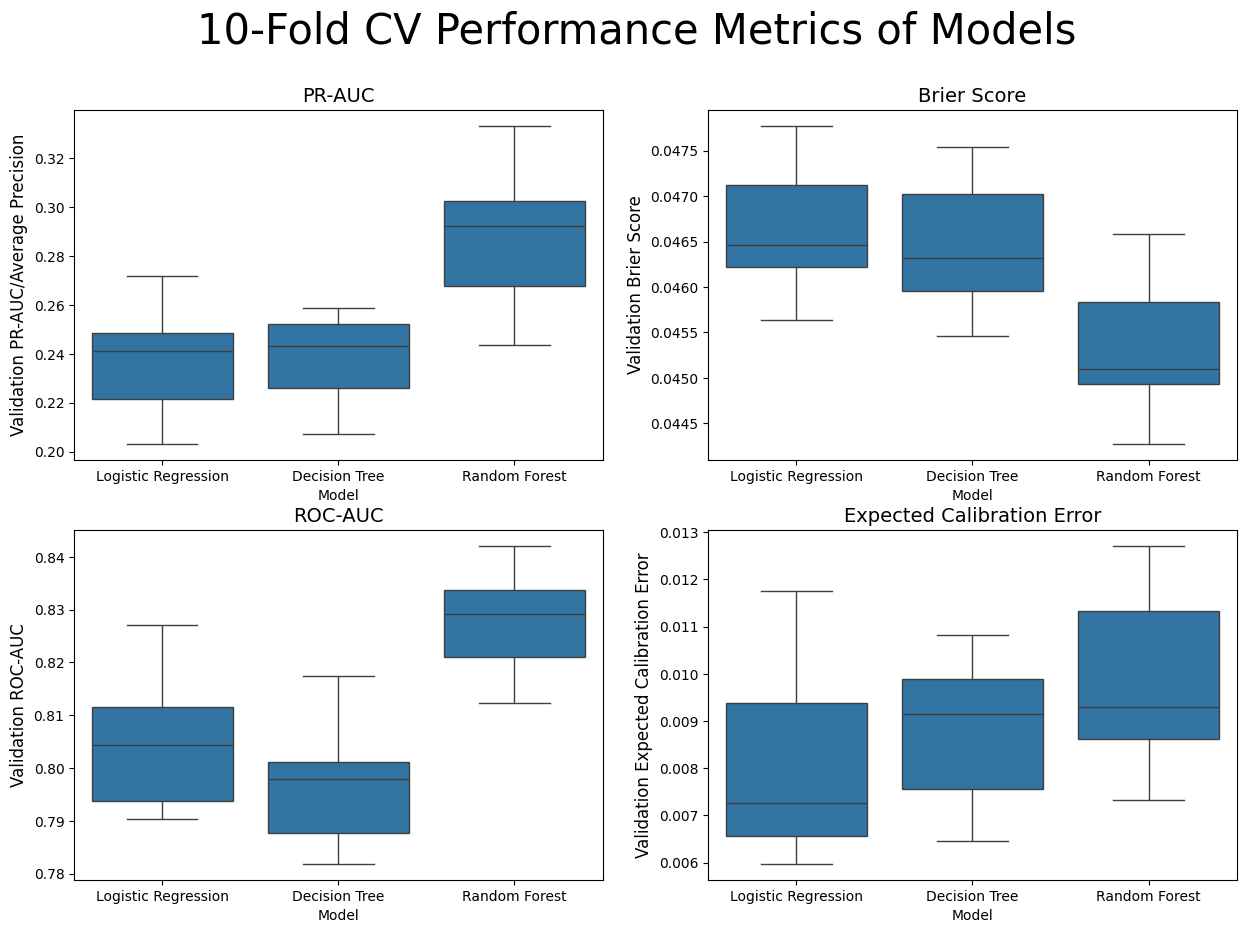

In [22]:
fig, axs = plt.subplots(2,2, figsize=(15,10))

sns.boxplot(scores, x = "Model", y = "test_average_precision", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[0,0])
axs[0,0].set_ylabel("Validation PR-AUC/Average Precision", fontsize=12)
axs[0,0].set_title("PR-AUC", fontsize=14)

sns.boxplot(scores, x = "Model", y = "test_brier_score", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[0,1])
axs[0,1].set_ylabel("Validation Brier Score", fontsize=12)
axs[0,1].set_title("Brier Score", fontsize=14)

sns.boxplot(scores, x = "Model", y = "test_roc_auc", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[1,0])
axs[1,0].set_ylabel("Validation ROC-AUC", fontsize=12)
axs[1,0].set_title("ROC-AUC", fontsize=14)

sns.boxplot(scores, x = "Model", y = "test_ece", order=["Logistic Regression", "Decision Tree", "Random Forest"], ax = axs[1,1])
axs[1,1].set_ylabel("Validation Expected Calibration Error", fontsize=12)
axs[1,1].set_title("Expected Calibration Error", fontsize=14)

plt.suptitle("10-Fold CV Performance Metrics of Models", fontsize=30)
plt.savefig(r"/Users/halos/Downloads/cv_models_boxplot.png", bbox_inches="tight")
plt.show()